# RL orchestrator vs the FrugalGPT LLM cascade (MMLU)

**Paper:** Chen, Zaharia, Zou (Stanford), *FrugalGPT: How to Use Large Language Models While Reducing Cost and Improving Performance* (arXiv 2305.05176; published in TMLR per the authors' repository).

**What the paper proposes (the LLM cascade):** send the query to a *list* of LLMs one after another, cheapest first.
After each answer a learned **generation scoring function** `g(query, answer) -> [0,1]` (the paper uses a DistilBERT regression
model trained to predict whether the answer is correct) judges how reliable it is. If the score clears that stage's **threshold**
the answer is returned and the remaining (more expensive) models are never called. The list of models and the thresholds are
chosen to maximise accuracy under an average-cost budget. Cascade length is 3 in the paper.

**How this differs from both RL and HybridLLM:** RL and HybridLLM call exactly one model per query, chosen from the query text alone.
A cascade can call several models per query and decides *after seeing their answers*. Its cost therefore includes the failed
attempts, and it needs every model's answers on the training questions to learn the scorer and thresholds.

**What this notebook does**
1. Reads the quality tables, RL checkpoints and HybridLLM results already produced by `03_rl_vs_hybridllm_mmlu.ipynb` (nothing there is changed).
2. Re-scores all 5 models once to keep each model's full A-D probabilities (the earlier run kept only correctness), and checks they agree with the earlier correctness.
3. Trains the scoring function per model: **(A)** DistilBERT regression on (question, model's answer), as in the paper; **(B)** a logistic regression on the model's own confidence (our extension, not in the paper: possible here because the models are open-weight).
4. Searches cascades (up to 3 models, all orders, threshold grids) on a tuning split, picks the best one for each cost budget, and evaluates on the held-out questions.
5. Compares with RL and HybridLLM on accuracy and cost, including total compute.

**Run order:** set `DRY_RUN = True` first (a few minutes, tiny slices), then `False`. Everything long is cached and resumable.

## Step 0: preflight (stops early with the exact fix if anything is missing)

In [1]:
import sys, importlib, os, json
os.environ["CUDA_VISIBLE_DEVICES"] = "0"      # must be set before torch is imported

REQUIRED = {"numpy": "numpy", "torch": "torch", "datasets": "datasets", "transformers": "transformers",
            "matplotlib": "matplotlib", "sentencepiece": "sentencepiece", "google.protobuf": "protobuf"}
missing = []
for mod, pip_name in REQUIRED.items():
    try:
        importlib.import_module(mod)
    except Exception:
        missing.append(pip_name)
if missing:
    raise RuntimeError("Missing packages: " + ", ".join(missing) +
        "\nInstall from a TERMINAL (pip inside Jupyter is blocked on this server), then restart the kernel:\n"
        "  " + sys.executable + " -m pip install " + " ".join(missing))

WORK = os.path.expanduser("~/hybridllm_project")
names = ["flan-t5-small", "flan-t5-base", "flan-t5-large", "flan-t5-xl", "llama-2-7b-chat"]
need = [f"{WORK}/ckpt_shared/mmlu_pool_examples.pkl", f"{WORK}/ckpt_shared/mmlu_holdout_examples.pkl",
        f"{WORK}/outputs/mmlu_quality_comparison.json", f"{WORK}/outputs/mmlu_rl_results.json"]
need += [f"{WORK}/ckpt_shared/mmlu_score_{s}_{n}.pkl" for n in names for s in ("pool", "holdout")]
absent = [p for p in need if not os.path.exists(p)]
if absent:
    raise RuntimeError("Files from the MMLU RL-vs-HybridLLM run not found:\n  " + "\n  ".join(absent))
_lam = json.load(open(f"{WORK}/outputs/mmlu_quality_comparison.json"))["lambda_rl"]
_ck = f"{WORK}/ckpt_shared/mmlu_rl_training_state_lam{_lam}.pkl"
if not os.path.exists(_ck):
    raise RuntimeError(f"RL checkpoint for the adopted lambda not found:\n  {_ck}")

import torch
if torch.cuda.is_available():
    free_gb = torch.cuda.mem_get_info()[0] / 1e9
    print(f"free GPU memory: {free_gb:.1f} GB")
    if free_gb < 20:
        print("WARNING: less than ~20 GB free. Llama needs ~14 GB in fp16; close other kernels and re-check nvidia-smi.")
else:
    print("WARNING: no GPU visible to torch")
print(f"preflight OK: packages present, MMLU caches found, RL checkpoint (lambda={_lam}) found.")

free GPU memory: 44.3 GB
preflight OK: packages present, MMLU caches found, RL checkpoint (lambda=0.25) found.


## Setup

In [2]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

import gc, math, json, random, pickle, shutil, time, itertools, csv
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from collections import Counter
from transformers import (AutoTokenizer, AutoModelForSeq2SeqLM, AutoModelForCausalLM, AutoModel,
                          AutoModelForSequenceClassification)
import matplotlib.pyplot as plt

SEED = 0
torch.manual_seed(SEED); random.seed(SEED); np.random.seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)
if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0), "| free GB:", round(torch.cuda.mem_get_info()[0] / 1e9, 1))

WORK_DIR = os.path.expanduser("~/hybridllm_project")
CKPT_DIR = os.path.join(WORK_DIR, "ckpt_shared")
OUTPUT_DIR = os.path.join(WORK_DIR, "outputs")
os.makedirs(CKPT_DIR, exist_ok=True); os.makedirs(OUTPUT_DIR, exist_ok=True)

def save_ckpt(name, obj):
    with open(f"{CKPT_DIR}/{name}.pkl", "wb") as f:
        pickle.dump(obj, f)

def load_ckpt(name):
    path = f"{CKPT_DIR}/{name}.pkl"
    if os.path.exists(path):
        with open(path, "rb") as f:
            return pickle.load(f)
    return None

def load_with_retry(model_class, model_id, **kwargs):
    try:
        return model_class.from_pretrained(model_id, **kwargs)
    except Exception as e:
        print(f"  [{model_id}] load failed ({type(e).__name__}); clearing cache and re-downloading...")
        cache_root = os.path.join(os.environ.get("HF_HOME", os.path.expanduser("~/.cache/huggingface")), "hub")
        target = os.path.join(cache_root, "models--" + model_id.replace("/", "--"))
        if os.path.exists(target):
            shutil.rmtree(target)
        return model_class.from_pretrained(model_id, force_download=True, **kwargs)

def free_gpu():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

def save_csv(name, header, rows):
    with open(os.path.join(OUTPUT_DIR, f"{FGTAG}{name}.csv"), "w", newline="", encoding="utf-8") as f:
        w = csv.writer(f); w.writerow(header); w.writerows(rows)

print("helpers ready.")

Device: cuda
GPU: NVIDIA L40S | free GB: 44.3
helpers ready.


## Config

In [3]:
DRY_RUN = False            # True = tiny smoke test (minutes, small slices). Set False for the real run.

SRC_TAG = "mmlu_"                                   # caches written by the MMLU RL-vs-HybridLLM notebook (read only)
FGTAG = ("dry_" if DRY_RUN else "") + "fg_mmlu_"    # every NEW cache/result file from this notebook starts with this

N_TRAIN_TOTAL = 9500      # same label-building slice as HybridLLM (first 9,500 pool questions)
N_SCORER_TRAIN = 6500     # part 1: trains the scoring functions
                          # part 2 (the remaining 3,000): tunes the cascade lists/thresholds on UNSEEN scorer outputs
HOLD_N = None             # None = all 1,531 held-out questions
MAX_CASCADE_LEN = 3       # as in the paper
N_THRESH = 25             # candidate thresholds per stage (quantiles of that model's scores on the tuning split)
SCORER_ID = "distilbert-base-uncased"               # the paper's scoring-function backbone
SCORER_EPOCHS, SCORER_LR, SCORER_BS, SCORER_MAXLEN = 3, 5e-5, 32, 384
SCORER_PARAMS = 66e6      # DistilBERT size, used only for the optional "cost incl. scorer overhead" column
ROUTER_ID = "microsoft/deberta-v3-small"
MAX_PROMPT_LEN = 512
LAMBDA_EVAL = 0.5         # fixed yardstick for "utility", identical to the earlier notebook
SCORE_BS = {"flan-t5-small": 128, "flan-t5-base": 128, "flan-t5-large": 64, "flan-t5-xl": 32, "llama-2-7b-chat": 32}

if DRY_RUN:
    N_TRAIN_TOTAL, N_SCORER_TRAIN, HOLD_N, SCORER_EPOCHS, N_THRESH = 300, 200, 200, 1, 8

MODEL_IDS = [
    ("flan-t5-small",   "google/flan-t5-small",            False, 80e6),
    ("flan-t5-base",    "google/flan-t5-base",             False, 250e6),
    ("flan-t5-large",   "google/flan-t5-large",            False, 780e6),
    ("flan-t5-xl",      "google/flan-t5-xl",               False, 3e9),
    ("llama-2-7b-chat", "NousResearch/Llama-2-7b-chat-hf", True,  7e9),
]
MODEL_NAMES = [m[0] for m in MODEL_IDS]
PARAMS = np.array([m[3] for m in MODEL_IDS])
COSTS = PARAMS / PARAMS.max()
N_ARMS = len(MODEL_IDS); K = N_ARMS
LLAMA_IDX = MODEL_NAMES.index("llama-2-7b-chat")

# fail fast: make sure the scorer backbone can be downloaded NOW, not 30 minutes from now
sc_tok = AutoTokenizer.from_pretrained(SCORER_ID)
_m = load_with_retry(AutoModelForSequenceClassification, SCORER_ID, num_labels=1); del _m; free_gpu()
print(f"scorer backbone ready ({SCORER_ID}) | DRY_RUN={DRY_RUN} | train={N_TRAIN_TOTAL} (scorer {N_SCORER_TRAIN} / tune {N_TRAIN_TOTAL - N_SCORER_TRAIN}) | cascade length <= {MAX_CASCADE_LEN}")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


scorer backbone ready (distilbert-base-uncased) | DRY_RUN=False | train=9500 (scorer 6500 / tune 3000) | cascade length <= 3


## Analysis utilities (numpy only)

Scoring-function quality (AUROC), the confidence-based scorer, the cascade search, and the paired bootstrap.

**Cascade cost** = sum of the (normalised-parameter) costs of every model actually called for that query, including the ones whose
answers were rejected. The search enumerates every ordered list of 1-3 distinct models and a quantile grid of thresholds, scores each on the tuning
split, and for each budget keeps the most accurate configuration whose average cost fits. This is an exhaustive version of the paper's optimiser (the paper prunes
the search; with 5 models the full grid is cheap).

In [4]:
def _avg_ranks(x):
    u, inv, cnt = np.unique(x, return_inverse=True, return_counts=True)
    csum = np.cumsum(cnt); start = csum - cnt + 1
    return ((start + csum) / 2.0)[inv]

def auroc(score, label):
    score = np.asarray(score, float); label = np.asarray(label) > 0.5
    n1 = int(label.sum()); n0 = len(label) - n1
    if n1 == 0 or n0 == 0:
        return float("nan")
    r = _avg_ranks(score)
    return float((r[label].sum() - n1 * (n1 + 1) / 2) / (n1 * n0))

def conf_features(P):
    # P: [N, 4] letter probabilities -> [p_max, margin to 2nd, entropy]
    P = np.clip(np.asarray(P, float), 1e-9, 1.0)
    s = np.sort(P, axis=1)[:, ::-1]
    return np.c_[s[:, 0], s[:, 0] - s[:, 1], -(P * np.log(P)).sum(1)]

def fit_logreg(X, y, l2=1e-2, iters=100):
    mu, sd = X.mean(0), X.std(0) + 1e-8
    Z = np.c_[np.ones(len(X)), (X - mu) / sd]; w = np.zeros(Z.shape[1])
    reg = np.r_[0.0, np.ones(Z.shape[1] - 1)] * l2
    for _ in range(iters):
        p = 1 / (1 + np.exp(-np.clip(Z @ w, -30, 30)))
        g = Z.T @ (p - y) + reg * w
        H = (Z * (p * (1 - p))[:, None]).T @ Z + np.diag(reg) + 1e-8 * np.eye(len(w))
        step = np.linalg.solve(H, g); w = w - step
        if np.abs(step).max() < 1e-7:
            break
    return {"w": w, "mu": mu, "sd": sd}

def predict_logreg(m, X):
    Z = np.c_[np.ones(len(X)), (X - m["mu"]) / m["sd"]]
    return 1 / (1 + np.exp(-np.clip(Z @ m["w"], -30, 30)))

def enumerate_cascades(sc, corr, costs, max_len, n_thresh):
    # sc, corr: [N, K] scorer output and 0/1 correctness of EACH model's answer on the tuning split.
    N, Kk = sc.shape
    grids = [np.unique(np.quantile(sc[:, j], np.linspace(0, 1, n_thresh))) for j in range(Kk)]
    out = []
    for a in range(Kk):
        out.append(((a,), (), float(corr[:, a].mean()), float(costs[a])))
    if max_len >= 2:
        for a, b in itertools.permutations(range(Kk), 2):
            Af = (sc[:, a][:, None] >= grids[a][None, :]).astype(np.float64)
            acc = (Af * corr[:, a][:, None]).sum(0) / N + ((1 - Af) * corr[:, b][:, None]).sum(0) / N
            cost = costs[a] + (1 - Af).mean(0) * costs[b]
            for t in range(len(grids[a])):
                out.append(((a, b), (float(grids[a][t]),), float(acc[t]), float(cost[t])))
    if max_len >= 3:
        for a, b, c in itertools.permutations(range(Kk), 3):
            Af = (sc[:, a][:, None] >= grids[a][None, :]).astype(np.float64); nA = 1 - Af
            Bf = (sc[:, b][:, None] >= grids[b][None, :]).astype(np.float64); nB = 1 - Bf
            acc = ((Af * corr[:, a][:, None]).sum(0)[:, None] + nA.T @ (Bf * corr[:, b][:, None])
                   + nA.T @ (nB * corr[:, c][:, None])) / N                     # [Ta, Tb]
            cost = costs[a] + nA.mean(0)[:, None] * costs[b] + (nA.T @ nB) / N * costs[c]
            for i in range(len(grids[a])):
                for j in range(len(grids[b])):
                    out.append(((a, b, c), (float(grids[a][i]), float(grids[b][j])), float(acc[i, j]), float(cost[i, j])))
    return out

def select_by_budget(cands, budgets):
    accs = np.array([c[2] for c in cands]); cs = np.array([c[3] for c in cands]); chosen = []
    for b in budgets:
        ok = np.where(cs <= b + 1e-12)[0]
        if len(ok) == 0:
            continue
        chosen.append(int(ok[np.lexsort((cs[ok], -accs[ok]))[0]]))
    return sorted(set(chosen))

def run_cascade(L, taus, sc, corr, costs):
    N = sc.shape[0]; alive = np.ones(N, bool)
    correct = np.zeros(N); cost = np.zeros(N); stage = np.zeros(N, int); calls = np.zeros(N)
    for s, m in enumerate(L):
        cost[alive] += costs[m]
        last = (s == len(L) - 1)
        if not last:
            calls[alive] += 1                       # the scoring function is only run when another stage could follow
        accept = alive.copy() if last else (alive & (sc[:, m] >= taus[s]))
        correct[accept] = corr[accept, m]; stage[accept] = s
        alive = alive & ~accept
    return correct, cost, stage, calls

def strategy_str(L, taus):
    parts = []
    for s, m in enumerate(L):
        parts.append(MODEL_NAMES[m] + (f" (accept if score >= {taus[s]:.2f})" if s < len(L) - 1 else " (final, always accepted)"))
    return "  ->  ".join(parts)

def paired_boot(a, b, n=2000, seed=0):
    d = np.asarray(a, float) - np.asarray(b, float)
    idx = np.random.RandomState(seed).randint(0, len(d), (n, len(d)))
    m = d[idx].mean(axis=1)
    return float(d.mean()), float(np.percentile(m, 2.5)), float(np.percentile(m, 97.5))

print("analysis utilities ready.")

analysis utilities ready.


## Data and cached results from the MMLU run

Same pool order, same first 9,500 questions as HybridLLM's label-building slice, same 1,531 held-out validation questions.
Quality tables, RL checkpoints and HybridLLM curves are loaded, not recomputed.

In [5]:
pool_all = load_ckpt(f"{SRC_TAG}pool_examples"); holdout_all = load_ckpt(f"{SRC_TAG}holdout_examples")
train = pool_all[:N_TRAIN_TOTAL]
holdout = holdout_all if HOLD_N is None else holdout_all[:HOLD_N]
NT, NH = len(train), len(holdout)
SPL = N_SCORER_TRAIN
idx_sc, idx_tune = np.arange(0, SPL), np.arange(SPL, NT)          # scorer-train / cascade-tuning split

CORR_train = np.zeros((NT, K)); CORR_hold = np.zeros((NH, K))     # cached correctness (single source of truth)
for j, name in enumerate(MODEL_NAMES):
    cp = load_ckpt(f"{SRC_TAG}score_pool_{name}"); ch = load_ckpt(f"{SRC_TAG}score_holdout_{name}")
    CORR_train[:, j] = [cp[i][0] for i in range(NT)]
    CORR_hold[:, j] = [ch[i][0] for i in range(NH)]
gold_train = np.array([ex["answer"] for ex in train]); gold_hold = np.array([ex["answer"] for ex in holdout])

src = json.load(open(os.path.join(OUTPUT_DIR, f"{SRC_TAG}quality_comparison.json")))
rl_src = json.load(open(os.path.join(OUTPUT_DIR, f"{SRC_TAG}rl_results.json")))
BEST_LAMBDA = src["lambda_rl"]
print(f"train={NT} (scorer {len(idx_sc)} / tune {len(idx_tune)}) | holdout={NH} | RL adopted lambda={BEST_LAMBDA}")
print("accuracy on holdout:", {n: round(float(CORR_hold[:, j].mean()), 3) for j, n in enumerate(MODEL_NAMES)})

train=9500 (scorer 6500 / tune 3000) | holdout=1531 | RL adopted lambda=0.25
accuracy on holdout: {'flan-t5-small': 0.293, 'flan-t5-base': 0.334, 'flan-t5-large': 0.42, 'flan-t5-xl': 0.498, 'llama-2-7b-chat': 0.456}


## Letter-token ids (same verification as the earlier notebook)

In [6]:
def get_t5_letter_ids(tok):
    ids = {}
    for letter in "ABCD":
        enc = tok.encode(letter, add_special_tokens=False)
        assert len(enc) == 1, f"T5 tokenizer: letter {letter!r} is not a single token: {enc}"
        ids[letter] = enc[0]
    return ids

def get_causal_letter_ids(tok, sample_prompt):
    base = tok.encode(sample_prompt, add_special_tokens=False)
    ids = {}
    for letter in "ABCD":
        full = tok.encode(sample_prompt + " " + letter, add_special_tokens=False)
        assert len(full) == len(base) + 1, f"Llama tokenizer: appending {letter!r} did not add exactly one token"
        ids[letter] = full[-1]
    return ids

LETTER_IDS = {}
for name, model_id, is_causal, _ in MODEL_IDS:
    tok = AutoTokenizer.from_pretrained(model_id)
    if is_causal:
        if tok.pad_token is None:
            tok.pad_token = tok.eos_token
        tok.padding_side = "left"
        LETTER_IDS[name] = get_causal_letter_ids(tok, pool_all[0]["prompt"])
    else:
        LETTER_IDS[name] = get_t5_letter_ids(tok)
    del tok
print("letter ids verified for all 5 tokenizers:", {n: list(v.values()) for n, v in LETTER_IDS.items()})

letter ids verified for all 5 tokenizers: {'flan-t5-small': [71, 272, 205, 309], 'flan-t5-base': [71, 272, 205, 309], 'flan-t5-large': [71, 272, 205, 309], 'flan-t5-xl': [71, 272, 205, 309], 'llama-2-7b-chat': [319, 350, 315, 360]}


## Step 1: re-score all 5 models, keeping the full A-D probabilities

The earlier run stored only (correct, P(correct)). The cascade needs each model's **chosen answer** and its **confidence**, so every model is run once more over the
training slice and the held-out set (one forward pass per question, no generation). The result is checked against the earlier correctness: they should agree on essentially every question
(tiny differences can come from batch padding in fp16).

In [7]:
def load_agent(name):
    _, model_id, is_causal, params = next(m for m in MODEL_IDS if m[0] == name)
    tok = AutoTokenizer.from_pretrained(model_id)
    if is_causal:
        tok.pad_token = tok.eos_token
        tok.padding_side = "left"
        model = load_with_retry(AutoModelForCausalLM, model_id, torch_dtype=torch.float16).to(DEVICE)
        n_emb = model.get_input_embeddings().num_embeddings
        print(f"  [{name}] pad_token_id={tok.pad_token_id}  embedding rows={n_emb}  len(tokenizer)={len(tok)}")
        assert tok.pad_token_id < n_emb, "pad token id is outside the embedding table"
    else:
        model = load_with_retry(AutoModelForSeq2SeqLM, model_id, torch_dtype=torch.float16).to(DEVICE)
    model.eval()
    return {"name": name, "tok": tok, "model": model, "causal": is_causal}

def free_agent(entry):
    del entry["model"], entry["tok"]
    free_gpu()

OOV_REPLACED = {"n": 0}

@torch.no_grad()
def score_batch(entry, prompts, letter_ids):
    tok, model = entry["tok"], entry["model"]
    enc = tok(prompts, return_tensors="pt", truncation=True, max_length=MAX_PROMPT_LEN, padding=True).to(DEVICE)
    letter_logit_ids = [letter_ids[l] for l in "ABCD"]
    if entry["causal"]:
        n_emb = model.get_input_embeddings().num_embeddings
        bad = enc["input_ids"] >= n_emb
        if bad.any():
            enc["input_ids"][bad] = tok.unk_token_id if tok.unk_token_id is not None else 0
            OOV_REPLACED["n"] += int(bad.sum())
        out = model(input_ids=enc["input_ids"], attention_mask=enc["attention_mask"], use_cache=False)
        logits = out.logits[:, -1, :]
    else:
        decoder_start = model.config.decoder_start_token_id
        dec_in = torch.full((enc["input_ids"].shape[0], 1), decoder_start, dtype=torch.long, device=DEVICE)
        out = model(input_ids=enc["input_ids"], attention_mask=enc["attention_mask"], decoder_input_ids=dec_in)
        logits = out.logits[:, 0, :]
    return torch.softmax(logits[:, letter_logit_ids].float(), dim=-1).cpu().numpy()

def run_probs(name, examples, cache_name):
    cache = load_ckpt(cache_name) or {}
    pending = [i for i in range(len(examples)) if i not in cache]
    if pending:
        entry = load_agent(name); letter_ids = LETTER_IDS[name]; bs = SCORE_BS[name]
        pending.sort(key=lambda i: -len(examples[i]["prompt"]))          # longest first: any OOM shows up immediately
        t0 = time.time(); n_batches = math.ceil(len(pending) / bs)
        for bi in range(n_batches):
            idxs = pending[bi * bs:(bi + 1) * bs]
            probs = score_batch(entry, [examples[i]["prompt"] for i in idxs], letter_ids)
            for i, p in zip(idxs, probs):
                cache[i] = p.astype(np.float32)
            if (bi + 1) % 10 == 0 or bi == n_batches - 1:
                save_ckpt(cache_name, cache)
                print(f"  [{name}] {len(cache)}/{len(examples)} | {(time.time()-t0)/60:.1f} min elapsed")
        free_agent(entry)
    return np.stack([cache[i] for i in range(len(examples))])

P_train = np.zeros((NT, K, 4), dtype=np.float32); P_hold = np.zeros((NH, K, 4), dtype=np.float32)
for j, name in enumerate(MODEL_NAMES):
    print(f"== {name}: training slice ({NT}) and held-out ({NH}) ==")
    P_train[:, j] = run_probs(name, train, f"{FGTAG}probs_train_{name}")
    P_hold[:, j] = run_probs(name, holdout, f"{FGTAG}probs_holdout_{name}")

PRED_train, PRED_hold = P_train.argmax(2), P_hold.argmax(2)              # [N, K] each model's chosen letter
print(f"\n{'model':>16} {'agree w/ earlier correctness':>30}")
for j, name in enumerate(MODEL_NAMES):
    agree = np.concatenate([(PRED_train[:, j] == gold_train) == (CORR_train[:, j] > 0.5),
                            (PRED_hold[:, j] == gold_hold) == (CORR_hold[:, j] > 0.5)]).mean()
    print(f"{name:>16} {100*agree:29.2f}%")
    assert agree > 0.95, f"{name}: re-scored answers disagree with the earlier run on >5% of questions; check the letter ids / prompts"

== flan-t5-small: training slice (9500) and held-out (1531) ==
== flan-t5-base: training slice (9500) and held-out (1531) ==
== flan-t5-large: training slice (9500) and held-out (1531) ==
== flan-t5-xl: training slice (9500) and held-out (1531) ==
== llama-2-7b-chat: training slice (9500) and held-out (1531) ==

           model   agree w/ earlier correctness
   flan-t5-small                         99.98%
    flan-t5-base                         99.97%
   flan-t5-large                         99.97%
      flan-t5-xl                         99.99%
 llama-2-7b-chat                         99.95%


## Step 2: how well can each model tell when it is right?

AUROC of the model's own confidence (max letter probability) as a predictor of correctness on the cascade-tuning split and on the held-out set (0.5 = no information, 1.0 = perfect).
This is the signal a cascade lives or dies on.

In [8]:
FEAT_train = np.stack([conf_features(P_train[:, j]) for j in range(K)], axis=1)     # [N, K, 3]
FEAT_hold = np.stack([conf_features(P_hold[:, j]) for j in range(K)], axis=1)
print(f"{'model':>16} {'acc(hold)':>10} {'mean p_max':>11} {'AUROC p_max (tune)':>20} {'AUROC p_max (hold)':>20}")
conf_auc = {}
for j, name in enumerate(MODEL_NAMES):
    a_t = auroc(FEAT_train[idx_tune, j, 0], CORR_train[idx_tune, j]); a_h = auroc(FEAT_hold[:, j, 0], CORR_hold[:, j])
    conf_auc[name] = {"tune": a_t, "hold": a_h}
    print(f"{name:>16} {100*CORR_hold[:, j].mean():9.1f}% {FEAT_hold[:, j, 0].mean():11.3f} {a_t:20.3f} {a_h:20.3f}")

           model  acc(hold)  mean p_max   AUROC p_max (tune)   AUROC p_max (hold)
   flan-t5-small      29.3%       0.424                0.517                0.542
    flan-t5-base      33.4%       0.566                0.592                0.588
   flan-t5-large      42.0%       0.627                0.632                0.666
      flan-t5-xl      49.8%       0.699                0.725                0.726
 llama-2-7b-chat      45.6%       0.773                0.701                0.718


## Step 3A: scoring function as in the paper (DistilBERT regression)

One DistilBERT regression model **per LLM**, trained on the scorer-train part to predict whether that LLM's answer is correct, from the text of the question and the answer letter
that LLM chose. Output = sigmoid(logit) in [0,1], trained with squared error (a regression, as the paper describes). Predictions are made on the tuning split (unseen by the scorer) and on the held-out set.

In [9]:
def _sc_batches(examples, letters, idxs, bs):
    for b in range(0, len(idxs), bs):
        ii = idxs[b:b + bs]
        yield ii, sc_tok([examples[i]["prompt"] for i in ii], [f"Model answer: {'ABCD'[letters[i]]}" for i in ii],
                         truncation="only_first", max_length=SCORER_MAXLEN, padding=True, return_tensors="pt")

def train_text_scorer(j, name):
    cache = load_ckpt(f"{FGTAG}scorerA_{name}")
    if cache is not None:
        return cache
    model = load_with_retry(AutoModelForSequenceClassification, SCORER_ID, num_labels=1).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=SCORER_LR)
    n = len(idx_sc); steps_total = max(1, SCORER_EPOCHS * math.ceil(n / SCORER_BS)); step = 0
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: max(0.0, 1.0 - s / steps_total))
    y_all = torch.tensor(CORR_train[:, j], dtype=torch.float32)
    t0 = time.time()
    for ep in range(SCORER_EPOCHS):
        model.train(); perm = np.random.permutation(idx_sc); tot = 0.0
        for ii, enc in _sc_batches(train, PRED_train[:, j], perm, SCORER_BS):
            enc = {k: v.to(DEVICE) for k, v in enc.items()}
            with torch.autocast(device_type="cuda", dtype=torch.bfloat16, enabled=(DEVICE == "cuda")):
                logit = model(**enc).logits.squeeze(-1)
            loss = F.mse_loss(torch.sigmoid(logit.float()), y_all[torch.as_tensor(ii)].to(DEVICE))
            opt.zero_grad(); loss.backward(); opt.step(); sched.step(); step += 1; tot += loss.item() * len(ii)
        print(f"  [scorer A / {name}] epoch {ep+1}/{SCORER_EPOCHS}  MSE={tot/n:.4f}  ({(time.time()-t0)/60:.1f} min)")
    model.eval()
    def predict(examples, letters, idxs):
        out = []
        with torch.no_grad():
            for ii, enc in _sc_batches(examples, letters, idxs, 128):
                enc = {k: v.to(DEVICE) for k, v in enc.items()}
                with torch.autocast(device_type="cuda", dtype=torch.bfloat16, enabled=(DEVICE == "cuda")):
                    out.extend(torch.sigmoid(model(**enc).logits.squeeze(-1).float()).cpu().tolist())
        return np.array(out)
    res = {"tune": predict(train, PRED_train[:, j], idx_tune), "hold": predict(holdout, PRED_hold[:, j], np.arange(NH))}
    save_ckpt(f"{FGTAG}scorerA_{name}", res)
    del model, opt; free_gpu()
    return res

SC_A_tune = np.zeros((len(idx_tune), K)); SC_A_hold = np.zeros((NH, K))
for j, name in enumerate(MODEL_NAMES):
    r = train_text_scorer(j, name)
    SC_A_tune[:, j], SC_A_hold[:, j] = r["tune"], r["hold"]
print(f"\n{'model':>16} {'scorer A AUROC (tune)':>22} {'scorer A AUROC (hold)':>22}")
for j, name in enumerate(MODEL_NAMES):
    print(f"{name:>16} {auroc(SC_A_tune[:, j], CORR_train[idx_tune, j]):22.3f} {auroc(SC_A_hold[:, j], CORR_hold[:, j]):22.3f}")


           model  scorer A AUROC (tune)  scorer A AUROC (hold)
   flan-t5-small                  0.532                  0.563
    flan-t5-base                  0.575                  0.549
   flan-t5-large                  0.610                  0.617
      flan-t5-xl                  0.663                  0.650
 llama-2-7b-chat                  0.667                  0.684


## Step 3B: scoring function from the model's own confidence (our extension)

The paper's scorer only sees text because commercial APIs expose nothing else. Our five models are open-weight, so we can also use their output probabilities.
A logistic regression per model on [max probability, margin to the second choice, entropy], fitted on the same scorer-train part.
This is **not** in the FrugalGPT paper; it is reported separately and labelled as an extension.

In [10]:
SC_B_tune = np.zeros((len(idx_tune), K)); SC_B_hold = np.zeros((NH, K)); logreg_models = {}
for j, name in enumerate(MODEL_NAMES):
    m = fit_logreg(FEAT_train[idx_sc, j], CORR_train[idx_sc, j]); logreg_models[name] = m
    SC_B_tune[:, j] = predict_logreg(m, FEAT_train[idx_tune, j]); SC_B_hold[:, j] = predict_logreg(m, FEAT_hold[:, j])
print(f"{'model':>16} {'scorer B AUROC (tune)':>22} {'scorer B AUROC (hold)':>22}")
for j, name in enumerate(MODEL_NAMES):
    print(f"{name:>16} {auroc(SC_B_tune[:, j], CORR_train[idx_tune, j]):22.3f} {auroc(SC_B_hold[:, j], CORR_hold[:, j]):22.3f}")

           model  scorer B AUROC (tune)  scorer B AUROC (hold)
   flan-t5-small                  0.515                  0.542
    flan-t5-base                  0.584                  0.578
   flan-t5-large                  0.630                  0.649
      flan-t5-xl                  0.718                  0.724
 llama-2-7b-chat                  0.699                  0.720


## Step 4: learn the cascades

For each scoring-function variant: enumerate all ordered lists of up to 3 models with a threshold grid, evaluate each on the **tuning split**, and for every budget keep the
most accurate configuration that fits. Budgets are a log grid plus the cost of every RL operating point, so each RL point has a directly comparable cascade.
The chosen configurations are then run on the **held-out** questions, which none of the scorers, lists or thresholds ever saw.

In [11]:
rl_costs = [r["cost"] for r in src["lambda_sweep_summary"]]
BUDGETS = sorted(set(np.round(np.geomspace(COSTS.min(), 1.8, 70), 5).tolist() + [round(c, 5) for c in rl_costs]))
corr_tune = CORR_train[idx_tune]
VARIANTS = {"A": ("FrugalGPT cascade (text scorer, as in paper)", SC_A_tune, SC_A_hold),
            "B": ("FrugalGPT cascade + confidence scorer (our extension)", SC_B_tune, SC_B_hold)}

cascade_results = {}
for key, (label, sc_tune, sc_hold) in VARIANTS.items():
    cands = enumerate_cascades(sc_tune, corr_tune, COSTS, MAX_CASCADE_LEN, N_THRESH)
    chosen = select_by_budget(cands, BUDGETS)
    pts = []
    for ci in chosen:
        L, taus, acc_t, cost_t = cands[ci]
        correct, cost, stage, calls = run_cascade(L, taus, sc_hold, CORR_hold, COSTS)
        pts.append({"L": L, "taus": taus, "tune_acc": acc_t, "tune_cost": cost_t, "correct": correct, "cost_vec": cost,
                    "accuracy": float(correct.mean()), "cost": float(cost.mean()),
                    "cost_with_scorer": float((cost + calls * SCORER_PARAMS / PARAMS.max()).mean()),
                    "stop_share": [float((stage == s).mean()) for s in range(len(L))],
                    "strategy": strategy_str(L, taus)})
    pts.sort(key=lambda p: p["cost"])
    cascade_results[key] = pts
    print(f"[{key}] {label}: {len(cands):,} candidate cascades searched, {len(pts)} budget operating points kept")
    for p in pts[::max(1, len(pts) // 8)]:
        print(f"    cost {p['cost']:.3f}  acc {100*p['accuracy']:.1f}%   {p['strategy']}")

[A] FrugalGPT cascade (text scorer, as in paper): 38,005 candidate cascades searched, 46 budget operating points kept
    cost 0.011  acc 29.3%   flan-t5-small (final, always accepted)
    cost 0.031  acc 31.4%   flan-t5-small (accept if score >= 0.25)  ->  flan-t5-base (accept if score >= 0.18)  ->  flan-t5-large (final, always accepted)
    cost 0.043  acc 32.7%   flan-t5-base (accept if score >= 0.18)  ->  flan-t5-small (accept if score >= 0.24)  ->  flan-t5-large (final, always accepted)
    cost 0.073  acc 34.6%   flan-t5-base (accept if score >= 0.36)  ->  flan-t5-small (accept if score >= 0.25)  ->  flan-t5-large (final, always accepted)
    cost 0.096  acc 38.9%   flan-t5-small (accept if score >= 0.35)  ->  flan-t5-large (final, always accepted)
    cost 0.132  acc 42.3%   flan-t5-large (accept if score >= 0.16)  ->  flan-t5-xl (accept if score >= 0.23)  ->  flan-t5-base (final, always accepted)
    cost 0.244  acc 43.4%   flan-t5-large (accept if score >= 0.24)  ->  flan-t5-b

## Step 5: the RL policies and HybridLLM results, from the earlier run

In [12]:
rl_tok = AutoTokenizer.from_pretrained(ROUTER_ID)

class OrchestratorHead(nn.Module):
    def __init__(self, hidden_size, n_agents):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(hidden_size, 128), nn.ReLU(), nn.Linear(128, n_agents))
    def forward(self, state):
        return self.net(state)

hold_prompts = [ex["prompt"] for ex in holdout]
def rl_values_for(lam):
    st = load_ckpt(f"{SRC_TAG}rl_training_state_lam{lam}")
    backbone = AutoModel.from_pretrained(ROUTER_ID, torch_dtype=torch.float32).to(DEVICE)
    backbone.load_state_dict(st["backbone_state"]); backbone.eval()
    head = OrchestratorHead(backbone.config.hidden_size, N_ARMS).to(DEVICE)
    head.load_state_dict(st["head_state"]); head.eval()
    vals = []
    with torch.no_grad():
        for b in range(0, len(hold_prompts), 32):
            enc = rl_tok(hold_prompts[b:b+32], return_tensors="pt", truncation=True, max_length=MAX_PROMPT_LEN, padding=True).to(DEVICE)
            vals.append(head(backbone(**enc).last_hidden_state[:, 0]).cpu().numpy())
    del backbone, head; free_gpu()
    return np.concatenate(vals)

ar = np.arange(NH)
rl_by_lam = {}
for r in src["lambda_sweep_summary"]:
    lam = r["lambda_trained"]
    ch = np.argmax(rl_values_for(lam), axis=1)
    rl_by_lam[lam] = {"choice": ch, "correct": CORR_hold[ar, ch], "cost": float(COSTS[ch].mean()), "accuracy": float(CORR_hold[ar, ch].mean())}
    print(f"RL lambda={lam}: cost {rl_by_lam[lam]['cost']:.3f}  accuracy {100*rl_by_lam[lam]['accuracy']:.1f}%   (earlier run reported {r['cost']:.3f} / {100*r['accuracy']:.1f}%)")
rl_best = rl_by_lam[BEST_LAMBDA]
hyb_curves = {lbl: d["curves"]["r_trans"] for lbl, d in src["pairs"].items()}
hyb_curves_det = {lbl: d["curves"]["r_det"] for lbl, d in src["pairs"].items()}

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
mask_predictions.classifier.weight      | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


RL lambda=0.05: cost 0.301  accuracy 42.8%   (earlier run reported 0.301 / 42.8%)


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

...

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
mask_predictions.classifier.weight      | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


RL lambda=1.0: cost 0.071  accuracy 38.5%   (earlier run reported 0.071 / 38.5%)


Loading weights:   0%|          | 0/102 [00:00<?, ?it/s]

[transformers] DebertaV2Model LOAD REPORT from: microsoft/deberta-v3-small
Key                                     | Status     |  | 
----------------------------------------+------------+--+-
mask_predictions.classifier.weight      | UNEXPECTED |  | 
mask_predictions.dense.weight           | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.bias   | UNEXPECTED |  | 
mask_predictions.classifier.bias        | UNEXPECTED |  | 
mask_predictions.dense.bias             | UNEXPECTED |  | 
lm_predictions.lm_head.LayerNorm.weight | UNEXPECTED |  | 
lm_predictions.lm_head.dense.weight     | UNEXPECTED |  | 
mask_predictions.LayerNorm.bias         | UNEXPECTED |  | 
mask_predictions.LayerNorm.weight       | UNEXPECTED |  | 
lm_predictions.lm_head.dense.bias       | UNEXPECTED |  | 
lm_predictions.lm_head.bias             | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


RL lambda=2.0: cost 0.036  accuracy 33.4%   (earlier run reported 0.036 / 33.4%)


## Step 6: results

**Table 1** scoring-function quality; **Table 2** RL vs cascades at matched cost with paired-bootstrap CIs; **Table 3** the best accuracy each approach can reach; **Table 4** total compute;
**Table 5** learned cascade strategies; **Table 6** per-query head-to-head.

In [13]:
def util(correct, cost):
    return float((np.where(correct > 0.5, 1, -1) - LAMBDA_EVAL * cost).mean())

# ---- Table 1: scoring-function quality ----
print("TABLE 1: how well each score separates right from wrong answers (AUROC on the held-out set)")
hdr1 = ["model", "acc_hold", "AUROC p_max", "AUROC scorer A (text)", "AUROC scorer B (confidence)"]
rows1 = [[n, round(float(CORR_hold[:, j].mean()), 3), round(conf_auc[n]["hold"], 3),
          round(auroc(SC_A_hold[:, j], CORR_hold[:, j]), 3), round(auroc(SC_B_hold[:, j], CORR_hold[:, j]), 3)] for j, n in enumerate(MODEL_NAMES)]
for r in [hdr1] + rows1: print("  " + " | ".join(f"{str(x):>26}" for x in r))
save_csv("table1_scorer_quality", hdr1, rows1)

# ---- Table 2: matched cost vs every RL operating point ----
print("\nTABLE 2: matched cost. For each RL policy, the cascade operating point nearest in cost (paired bootstrap 95% CI of RL - cascade accuracy)")
hdr2 = ["RL lambda", "RL cost", "RL acc", "cascade", "casc cost", "casc acc", "RL - casc", "95% CI", "verdict"]
rows2 = []; matched = {}
for lam, rl in rl_by_lam.items():
    for key, pts in cascade_results.items():
        p = min(pts, key=lambda q: abs(q["cost"] - rl["cost"]))
        diff, lo, hi = paired_boot(rl["correct"], p["correct"])
        verdict = "RL better" if lo > 0 else ("cascade better" if hi < 0 else "no significant difference")
        matched[(lam, key)] = {"rl_cost": rl["cost"], "rl_acc": rl["accuracy"], "casc_cost": p["cost"], "casc_acc": p["accuracy"],
                               "diff": diff, "ci95": [lo, hi], "verdict": verdict, "strategy": p["strategy"], "casc_correct": p["correct"]}
        rows2.append([lam, round(rl["cost"], 3), f"{100*rl['accuracy']:.1f}%", key, round(p["cost"], 3), f"{100*p['accuracy']:.1f}%",
                      f"{100*diff:+.1f} pt", f"[{100*lo:+.1f}, {100*hi:+.1f}]", verdict])
for r in [hdr2] + rows2: print("  " + " | ".join(f"{str(x):>14}" for x in r))
save_csv("table2_matched_cost", hdr2, rows2)

# ---- Table 3: best accuracy reachable ----
print("\nTABLE 3: accuracy ceiling and cost of the best configuration each approach offers")
best_single = int(np.argmax(CORR_hold.mean(0)))
rows3 = [[f"best single model ({MODEL_NAMES[best_single]})", round(float(COSTS[best_single]), 3), f"{100*CORR_hold[:, best_single].mean():.1f}%"],
         ["always Llama-2-7b-chat", 1.0, f"{100*CORR_hold[:, LLAMA_IDX].mean():.1f}%"],
         [f"RL (adopted, lambda={BEST_LAMBDA})", round(rl_best["cost"], 3), f"{100*rl_best['accuracy']:.1f}%"],
         ["RL, highest-accuracy policy among trained lambdas", round(max(rl_by_lam.values(), key=lambda r: r['accuracy'])['cost'], 3),
          f"{100*max(r['accuracy'] for r in rl_by_lam.values()):.1f}%"]]
for lbl, d in src["pairs"].items():
    top = max(d["curves"]["r_trans"] + d["curves"]["r_det"], key=lambda x: x["accuracy"])
    rows3.append([f"HybridLLM {lbl}, best threshold (on held-out)", round(top["cost"], 3), f"{100*top['accuracy']:.1f}%"])
for key, pts in cascade_results.items():
    top = max(pts, key=lambda q: (q["tune_acc"], -q["tune_cost"]))        # picked on the TUNING split, reported on held-out
    rows3.append([f"cascade {key}, largest budget (picked on tuning split)", round(top["cost"], 3), f"{100*top['accuracy']:.1f}%"])
rows3.append(["oracle: cheapest correct model", round(float(np.mean([COSTS[int(np.argmax(r > 0.5))] if (r > 0.5).any() else COSTS[LLAMA_IDX] for r in CORR_hold])), 3),
              f"{100*(CORR_hold.max(1) > 0.5).mean():.1f}%"])
hdr3 = ["approach", "avg cost", "accuracy"]
for r in [hdr3] + rows3: print("  " + " | ".join(f"{str(x):>52}" if i == 0 else f"{str(x):>10}" for i, x in enumerate(r)))
save_csv("table3_ceiling", hdr3, rows3)

# ---- Table 4: total compute ----
print("\nTABLE 4: total compute in trillions of parameter-calls (training/label-building + serving the held-out set at the matched point)")
rl_total = float(rl_src["total_cost_raw_params"]) if "total_cost_raw_params" in rl_src else float(sum(PARAMS[MODEL_NAMES.index(a)] for a in rl_src["action_log"]))
serve_rl = NH * rl_best["cost"] * PARAMS.max()
rows4 = [["RL (online over the pool; includes learning)", "-", round(rl_total / 1e12, 1), round(serve_rl / 1e12, 2), round((rl_total + serve_rl) / 1e12, 1)]]
for lbl, d in src["pairs"].items():
    S, L_ = MODEL_NAMES.index(d["small"]), MODEL_NAMES.index(d["large"])
    lb = src["n_train_hybrid"] * (PARAMS[S] + PARAMS[L_])
    near = min(d["curves"]["r_trans"], key=lambda x: abs(x["cost"] - rl_best["cost"]))
    serve = NH * near["cost"] * PARAMS.max()
    rows4.append([f"HybridLLM {lbl} ({d['small']} + {d['large']})", near["cost"].__round__(3), round(lb / 1e12, 1), round(serve / 1e12, 2), round((lb + serve) / 1e12, 1)])
lb_fg = NT * PARAMS.sum()
for key, pts in cascade_results.items():
    p = min(pts, key=lambda q: abs(q["cost"] - rl_best["cost"])); serve = NH * p["cost"] * PARAMS.max()
    rows4.append([f"FrugalGPT cascade {key} (needs all 5 models on {NT} train questions)", round(p["cost"], 3), round(lb_fg / 1e12, 1), round(serve / 1e12, 2), round((lb_fg + serve) / 1e12, 1)])
hdr4 = ["system", "serve cost/query", "training or label-building (T)", "serving held-out (T)", "total (T)"]
for r in [hdr4] + rows4: print("  " + " | ".join(f"{str(x):>58}" if i == 0 else f"{str(x):>16}" for i, x in enumerate(r)))
save_csv("table4_total_compute", hdr4, rows4)

# ---- Table 5: learned cascades (like the paper's Figure 3) ----
print("\nTABLE 5: learned cascade strategies at the cost of each RL policy")
rows5 = []
for lam in rl_by_lam:
    for key in cascade_results:
        m = matched[(lam, key)]
        rows5.append([f"RL lambda={lam} (cost {m['rl_cost']:.3f})", key, f"{m['casc_cost']:.3f}", f"{100*m['casc_acc']:.1f}%", m["strategy"]])
for r in rows5: print("  ", " | ".join(str(x) for x in r))
save_csv("table5_strategies", ["matched to", "variant", "cost", "accuracy", "strategy"], rows5)

# ---- Table 6: per-query head-to-head at the adopted RL policy ----
print(f"\nTABLE 6: per-query head-to-head, % of held-out questions (RL lambda={BEST_LAMBDA} vs the nearest-cost cascade)")
hdr6 = ["cascade", "both correct", "only RL correct", "only cascade correct", "both wrong"]
rows6 = []
for key in cascade_results:
    c = matched[(BEST_LAMBDA, key)]["casc_correct"] > 0.5; r_ = rl_best["correct"] > 0.5
    rows6.append([key] + [round(100 * float(x.mean()), 1) for x in [r_ & c, r_ & ~c, ~r_ & c, ~r_ & ~c]])
for r in [hdr6] + rows6: print("  " + " | ".join(f"{str(x):>22}" for x in r))
save_csv("table6_head_to_head", hdr6, rows6)

TABLE 1: how well each score separates right from wrong answers (AUROC on the held-out set)
                       model |                   acc_hold |                AUROC p_max |      AUROC scorer A (text) | AUROC scorer B (confidence)
               flan-t5-small |                      0.293 |                      0.542 |                      0.563 |                      0.542
                flan-t5-base |                      0.334 |                      0.588 |                      0.549 |                      0.578
               flan-t5-large |                       0.42 |                      0.666 |                      0.617 |                      0.649
                  flan-t5-xl |                      0.498 |                      0.726 |                       0.65 |                      0.724
             llama-2-7b-chat |                      0.456 |                      0.718 |                      0.684 |                       0.72

TABLE 2: matched cost. For each RL p

## Plot and export

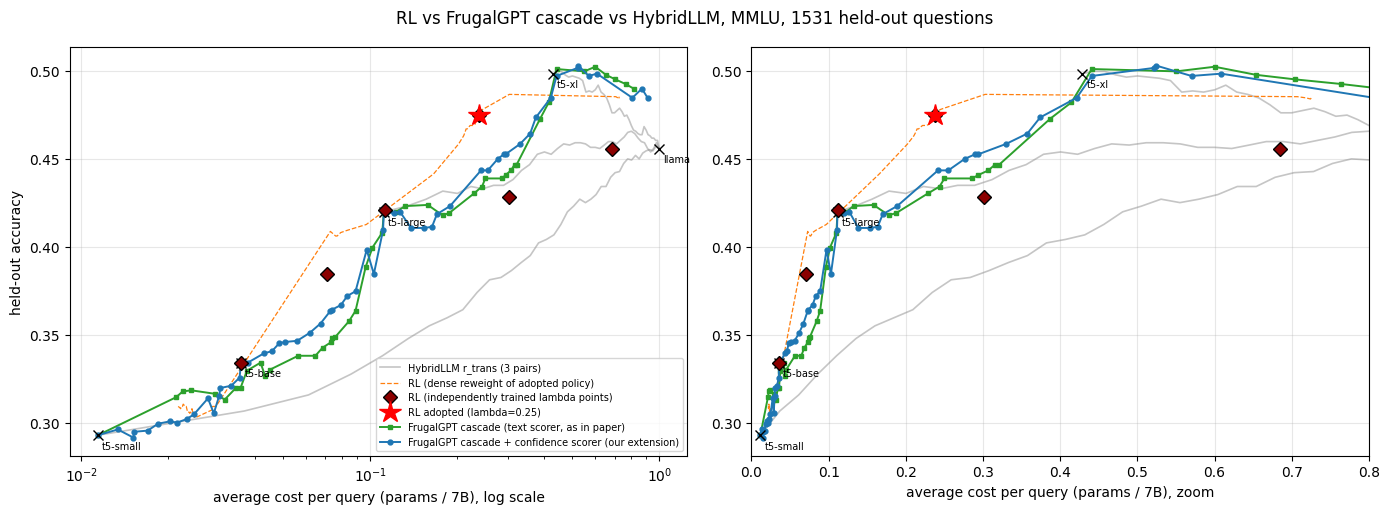

saved /home/bhavana.ravi/hybridllm_project/outputs/fg_mmlu_comparison.json


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2))
for ai, (xlog, xmax) in zip(axes, [(True, None), (False, 0.8)]):
    for lbl, pts in hyb_curves.items():
        pts = sorted(pts, key=lambda x: x["cost"])
        ai.plot([x["cost"] for x in pts], [x["accuracy"] for x in pts], "-", color="tab:gray", alpha=0.45, lw=1.2,
                label="HybridLLM r_trans (3 pairs)" if lbl == "large_gap" else None)
    pts = sorted(src["rl_curve"], key=lambda x: x["cost"])
    ai.plot([x["cost"] for x in pts], [x["accuracy"] for x in pts], "--", color="tab:orange", lw=0.9, label="RL (dense reweight of adopted policy)")
    ai.plot([r["cost"] for r in src["lambda_sweep_summary"]], [r["accuracy"] for r in src["lambda_sweep_summary"]], "D", color="darkred", ms=7,
            markeredgecolor="black", label="RL (independently trained lambda points)", zorder=6)
    ai.plot(rl_best["cost"], rl_best["accuracy"], "*", color="red", ms=16, label=f"RL adopted (lambda={BEST_LAMBDA})", zorder=7)
    for key, (c, mk) in {"A": ("tab:green", "s"), "B": ("tab:blue", "o")}.items():
        pts = cascade_results[key]
        ai.plot([p["cost"] for p in pts], [p["accuracy"] for p in pts], "-" + mk, color=c, ms=3.5, lw=1.4, label=VARIANTS[key][0])
    for j, n in enumerate(MODEL_NAMES):
        ai.plot(COSTS[j], CORR_hold[:, j].mean(), "kx", ms=7)
        ai.annotate(n.replace("flan-t5-", "t5-").replace("llama-2-7b-chat", "llama"), (COSTS[j], CORR_hold[:, j].mean()), textcoords="offset points", xytext=(3, -10), fontsize=7)
    if xlog: ai.set_xscale("log")
    else: ai.set_xlim(0, xmax)
    ai.grid(alpha=0.3); ai.set_xlabel("average cost per query (params / 7B)" + (", log scale" if xlog else ", zoom"))
axes[0].set_ylabel("held-out accuracy"); axes[0].legend(fontsize=7, loc="lower right")
plt.suptitle(f"RL vs FrugalGPT cascade vs HybridLLM, MMLU, {NH} held-out questions"); plt.tight_layout()
fig.savefig(os.path.join(OUTPUT_DIR, f"{FGTAG}accuracy_vs_cost.png"), dpi=150); plt.show()

def _clean(p): return {k: v for k, v in p.items() if k not in ("correct", "cost_vec")}
out = {"n_holdout": NH, "n_train": NT, "n_scorer_train": int(len(idx_sc)), "n_tune": int(len(idx_tune)), "max_cascade_len": MAX_CASCADE_LEN,
       "scorer_id": SCORER_ID, "lambda_rl": BEST_LAMBDA,
       "scorer_quality": {r[0]: {"acc": r[1], "auroc_pmax": r[2], "auroc_A": r[3], "auroc_B": r[4]} for r in rows1},
       "cascades": {k: [_clean(p) for p in pts] for k, pts in cascade_results.items()},
       "rl_points": {str(lam): {"cost": r["cost"], "accuracy": r["accuracy"]} for lam, r in rl_by_lam.items()},
       "matched": {f"{lam}|{key}": {k: v for k, v in m.items() if k != "casc_correct"} for (lam, key), m in matched.items()},
       "total_compute_T": {r[0]: {"train": r[2], "serve": r[3], "total": r[4]} for r in rows4}}
with open(os.path.join(OUTPUT_DIR, f"{FGTAG}comparison.json"), "w") as f:
    json.dump(out, f, indent=2, default=float)
print("saved", os.path.join(OUTPUT_DIR, f"{FGTAG}comparison.json"))